In [1]:
!nvidia-smi

Sun Oct 25 18:19:23 2026       
+-----------------------------------------------------------------------------------------+
| NVIDIA-SMI 580.82.07              Driver Version: 580.82.07      CUDA Version: 13.0     |
+-----------------------------------------+------------------------+----------------------+
| GPU  Name                 Persistence-M | Bus-Id          Disp.A | Volatile Uncorr. ECC |
| Fan  Temp   Perf          Pwr:Usage/Cap |           Memory-Usage | GPU-Util  Compute M. |
|                                         |                        |               MIG M. |
|=========================================+========================+======================|
|   0  Tesla T4                       Off |   00000000:00:04.0 Off |                    0 |
| N/A   38C    P8             10W /   70W |       0MiB /  15360MiB |      0%      Default |
|                                         |                        |                  N/A |
+-----------------------------------------+-----

In [2]:
from google.colab import drive
drive.mount('/content/drive')

Mounted at /content/drive


In [3]:
!pip install -q timm transformers albumentations torchmetrics tqdm

In [4]:
from google.colab import files
uploaded = files.upload()

Saving project.zip to project.zip


In [5]:
import zipfile, os, time

# --- 1. Распаковка project.zip (с исправлением Windows-путей) ---
PROJECT = "/content/calorie-project"
os.makedirs(PROJECT, exist_ok=True)

with zipfile.ZipFile("project.zip", "r") as zf:
    for member in zf.namelist():
        if member.endswith("/") or member.endswith("\\"):
            continue
        fixed = member.replace("\\", "/")
        target = os.path.join(PROJECT, fixed)
        os.makedirs(os.path.dirname(target), exist_ok=True)
        with zf.open(member) as src, open(target, "wb") as dst:
            dst.write(src.read())
print("✅ project.zip распакован")

# --- 2. Распаковка картинок ---
IMAGES_ARCHIVE = "/content/drive/MyDrive/calorie-project/data/images.zip"
if not os.path.exists("/content/data/images"):
    print("Распаковываю images.zip...")
    t0 = time.time()
    os.makedirs("/content/data", exist_ok=True)
    with zipfile.ZipFile(IMAGES_ARCHIVE, "r") as zf:
        zf.extractall("/content/data")
    print(f"✅ Картинки распакованы за {time.time()-t0:.0f} сек")
else:
    print("✅ Картинки уже распакованы")

print("   Папок:", len(os.listdir("/content/data/images")))

# --- 3. Симлинк data/images ---
os.chdir(PROJECT)
link = os.path.join(PROJECT, "data", "images")
if os.path.islink(link):
    os.unlink(link)
if not os.path.exists(link):
    os.symlink("/content/data/images", link)
print("✅ Симлинк:", os.path.realpath(link))

# --- 4. Проверка правок в скриптах ---
with open("scripts/utils.py") as f:    utils = f.read()
with open("scripts/config.py") as f:   config = f.read()

checks = {
    "utils: torch.amp":            "from torch.amp import" in utils,
    "utils: GradScaler('cuda')":   'GradScaler("cuda", enabled=use_amp)' in utils,
    "utils: autocast('cuda')":     'autocast("cuda", enabled=use_amp)' in utils,
    "config: NUM_WORKERS = 0":     "self.NUM_WORKERS = 0" in config,
}
print("\n=== Проверка правок ===")
for name, ok in checks.items():
    print(f"  {'✅' if ok else '❌'} {name}")

# --- 5. Финальная сводка ---
import pandas as pd
dish = pd.read_csv("data/dish.csv")
ingr = pd.read_csv("data/ingredients.csv")
print("\n=== Итог ===")
print(f"  dish.csv:        {dish.shape[0]} строк")
print(f"  ingredients.csv: {ingr.shape[0]} строк")
print(f"  images/:         {len(os.listdir('data/images'))} папок")
print(f"  scripts/:        {sorted(os.listdir('scripts'))}")

✅ project.zip распакован
Распаковываю images.zip...
✅ Картинки распакованы за 42 сек
   Папок: 3490
✅ Симлинк: /content/data/images

=== Проверка правок ===
  ✅ utils: torch.amp
  ✅ utils: GradScaler('cuda')
  ✅ utils: autocast('cuda')
  ✅ config: NUM_WORKERS = 0

=== Итог ===
  dish.csv:        3262 строк
  ingredients.csv: 555 строк
  images/:         3490 папок
  scripts/:        ['__init__.py', 'config.py', 'dataset.py', 'utils.py']


In [6]:
# =====================================================================
# 0. Импорты и seed
# =====================================================================
import os, sys, time
import numpy as np
import pandas as pd
import torch
from sklearn.model_selection import train_test_split
from transformers import AutoTokenizer

PROJECT_DIR = "/content/calorie-project"
os.chdir(PROJECT_DIR)
if PROJECT_DIR not in sys.path:
    sys.path.insert(0, PROJECT_DIR)

from scripts.config import Config
from scripts.dataset import (
    DishDataset,
    get_train_transforms,
    get_valid_transforms,
    build_dataloaders,
)
from scripts.utils import (
    seed_everything,
    MultiModalCalorieModel,
    train,
    evaluate_on_test,
    load_checkpoint,
)

# =====================================================================
# 1. Загрузка данных и маппинг ингредиентов
# =====================================================================
dish = pd.read_csv("data/dish.csv")
ingr = pd.read_csv("data/ingredients.csv")

ingr_mapping = dict(zip(ingr["id"], ingr["ingr"]))

def map_ingredients(ingr_string):
    if pd.isna(ingr_string):
        return ""
    names = []
    for raw in ingr_string.split(";"):
        raw = raw.strip()
        if not raw:
            continue
        try:
            num = int(raw.replace("ingr_", ""))
            if num in ingr_mapping:
                names.append(ingr_mapping[num])
        except ValueError:
            continue
    return ", ".join(names)

dish["ingredients_clean"] = dish["ingredients"].apply(map_ingredients)

# =====================================================================
# 2. Конфиг + seed
# =====================================================================
cfg = Config()
seed_everything(cfg.SEED)
print(cfg.summary())

# =====================================================================
# 3. Сплит
# =====================================================================
train_full = dish[dish["split"] == "train"].reset_index(drop=True)
test       = dish[dish["split"] == "test"].reset_index(drop=True)

train_part, val_part = train_test_split(
    train_full, test_size=cfg.VAL_SPLIT, random_state=cfg.SEED
)
train_part = train_part.reset_index(drop=True)
val_part   = val_part.reset_index(drop=True)

print(f"\ntrain_part: {len(train_part)} | val_part: {len(val_part)} | test: {len(test)}")

# =====================================================================
# 4. Статистики нормализации
# =====================================================================
train_part["density"] = (
    train_part["total_calories"] / (train_part["total_mass"] + 1e-6) * 100
)
cfg.TARGET_MEAN = float(train_part["density"].mean())
cfg.TARGET_STD  = float(train_part["density"].std())
cfg.MASS_MEAN   = float(train_part["total_mass"].mean())
cfg.MASS_STD    = float(train_part["total_mass"].std())

print(f"\ndensity: mean={cfg.TARGET_MEAN:.2f}, std={cfg.TARGET_STD:.2f}")
print(f"mass:    mean={cfg.MASS_MEAN:.2f},  std={cfg.MASS_STD:.2f}")

# =====================================================================
# 5. Токенизатор и датасеты
# =====================================================================
tokenizer = AutoTokenizer.from_pretrained(cfg.TEXT_MODEL)

def make_ds(df, transform):
    return DishDataset(
        df=df, images_dir=cfg.IMAGES_DIR, transform=transform,
        tokenizer=tokenizer, max_length=cfg.MAX_LENGTH,
        target_mean=cfg.TARGET_MEAN, target_std=cfg.TARGET_STD,
        mass_mean=cfg.MASS_MEAN, mass_std=cfg.MASS_STD,
        validate_paths=True,
    )

train_dataset = make_ds(train_part, get_train_transforms(
    cfg.IMG_SIZE, cfg.AUG_SCALE_MIN, cfg.AUG_FLIP_P, cfg.AUG_COLOR_P,
))
valid_dataset = make_ds(val_part,   get_valid_transforms(cfg.IMG_SIZE))
test_dataset  = make_ds(test,       get_valid_transforms(cfg.IMG_SIZE))

print(f"\nДатасеты: Train={len(train_dataset)} | Val={len(valid_dataset)} | Test={len(test_dataset)}")

# =====================================================================
# 6. Обучение
# =====================================================================
t_start = time.time()
trained_model, history = train(cfg, train_dataset, valid_dataset)
print(f"\nОбщее время обучения: {(time.time() - t_start)/60:.1f} мин")

print("\n=== История обучения ===")
print(history.round(3).to_string(index=False))

=== Config ===
  DEVICE:         cuda
  TEXT_MODEL:     distilbert-base-uncased
  IMAGE_MODEL:    efficientnet_b0
  IMG_SIZE:       224
  MAX_LENGTH:     64
  HIDDEN_DIM:     256
  BATCH_SIZE:     4
  EPOCHS:         20
  TEXT_LR:        1e-05
  IMAGE_LR:       0.0001
  CLASSIFIER_LR:  0.001
  WEIGHT_DECAY:   0.01
  USE_AMP:        True
  NUM_WORKERS:    0
  VAL_SPLIT:      0.15
  SAVE_PATH:      best_calorie_model.pth

train_part: 2341 | val_part: 414 | test: 507

density: mean=128.21, std=104.72
mass:    mean=217.17,  std=164.98


config.json:   0%|          | 0.00/483 [00:00<?, ?B/s]

tokenizer_config.json:   0%|          | 0.00/48.0 [00:00<?, ?B/s]

vocab.txt:   0%|          | 0.00/232k [00:00<?, ?B/s]

tokenizer.json:   0%|          | 0.00/466k [00:00<?, ?B/s]

[DishDataset] size=2341, images_dir=data/images, transform=yes
[DishDataset] size=414, images_dir=data/images, transform=yes
[DishDataset] size=507, images_dir=data/images, transform=yes

Датасеты: Train=2341 | Val=414 | Test=507
=== Config ===
  DEVICE:         cuda
  TEXT_MODEL:     distilbert-base-uncased
  IMAGE_MODEL:    efficientnet_b0
  IMG_SIZE:       224
  MAX_LENGTH:     64
  HIDDEN_DIM:     256
  BATCH_SIZE:     4
  EPOCHS:         20
  TEXT_LR:        1e-05
  IMAGE_LR:       0.0001
  CLASSIFIER_LR:  0.001
  WEIGHT_DECAY:   0.01
  USE_AMP:        True
  NUM_WORKERS:    0
  VAL_SPLIT:      0.15
  SAVE_PATH:      best_calorie_model.pth


... (43 outputs left out)

Epoch 19/20 [Train]:   0%|          | 0/586 [00:00<?, ?it/s]

--> Epoch 19 |  98.2s | train_loss=0.1299 | train_densMAE=13.59 | val_densMAE=0.11 | val_CAL_MAE=25.81 | lr_head=2.50e-04


Epoch 20/20 [Train]:   0%|          | 0/586 [00:00<?, ?it/s]

--> Epoch 20 |  98.9s | train_loss=0.1312 | train_densMAE=13.75 | val_densMAE=0.10 | val_CAL_MAE=23.90 | lr_head=2.50e-04
    [+] Новый best (val_cal_MAE=23.90). Сохранено.

=== Обучение завершено ===
Лучшая эпоха: 20, best val_cal_MAE: 23.90 ккал

Общее время обучения: 33.7 мин

=== История обучения ===
 epoch  train_loss  val_density_mae  val_calories_mae  time_sec
     1       0.454            0.299            55.252   115.616
     2       0.292            0.216            49.017    98.317
     3       0.262            0.183            38.799    97.778
     4       0.242            0.166            34.879    97.600
     5       0.232            0.178            35.732    98.068
     6       0.222            0.184            35.522    97.859
     7       0.212            0.175            36.124    97.746
     8       0.185            0.121            27.152    97.645
     9       0.169            0.139            31.594    97.763
    10       0.173            0.150            31.281 

In [7]:
import os
p = "/content/calorie-project/best_calorie_model.pth"
print(f"Размер: {os.path.getsize(p)/1e6:.1f} MB")

Размер: 284.5 MB


Loading weights:   0%|          | 0/100 [00:00<?, ?it/s]

[transformers] DistilBertModel LOAD REPORT from: distilbert-base-uncased
Key                     | Status     |  | 
------------------------+------------+--+-
vocab_layer_norm.bias   | UNEXPECTED |  | 
vocab_transform.bias    | UNEXPECTED |  | 
vocab_layer_norm.weight | UNEXPECTED |  | 
vocab_projector.bias    | UNEXPECTED |  | 
vocab_transform.weight  | UNEXPECTED |  | 

Notes:
- UNEXPECTED:	can be ignored when loading from different task/architecture; not ok if you expect identical arch.


Test inference:   0%|          | 0/507 [00:00<?, ?it/s]


Test MAE: 32.34 ккал
Медиана ошибки: 9.97
90-й перцентиль: 84.63

Финальный MAE на test: 32.34 ккал
✅ ЦЕЛЬ ДОСТИГНУТА (MAE < 50)


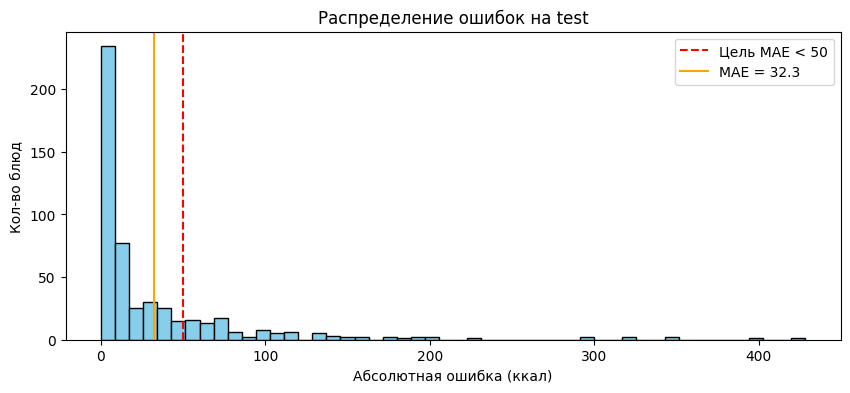


=== ТОП-5 худших предсказаний ===
        dish_id  true_calories  pred_calories  error  true_mass
dish_1558720236          887.8          459.4  428.4      407.0
dish_1558630325          751.5          353.7  397.9      269.0
dish_1566328805          927.8          579.5  348.3      488.0
dish_1566328831          941.6          598.5  343.1      500.0
dish_1558373159         1013.3          688.2  325.2      334.0


In [8]:
# Инференс на test
df_test, model_eval, ckpt = evaluate_on_test(cfg, test_dataset)

# Гистограмма ошибок
import matplotlib.pyplot as plt

final_mae = df_test["error"].mean()
print(f"\nФинальный MAE на test: {final_mae:.2f} ккал")
print("✅ ЦЕЛЬ ДОСТИГНУТА (MAE < 50)" if final_mae < 50 else "❌ MAE >= 50")

plt.figure(figsize=(10, 4))
plt.hist(df_test["error"], bins=50, color="skyblue", edgecolor="black")
plt.axvline(50, color="red", ls="--", label="Цель MAE < 50")
plt.axvline(final_mae, color="orange", ls="-", label=f"MAE = {final_mae:.1f}")
plt.legend()
plt.title("Распределение ошибок на test")
plt.xlabel("Абсолютная ошибка (ккал)")
plt.ylabel("Кол-во блюд")
plt.show()

# Топ-5 худших
top5 = df_test.nlargest(5, "error").reset_index(drop=True)
print("\n=== ТОП-5 худших предсказаний ===")
print(top5[["dish_id", "true_calories", "pred_calories", "error", "true_mass"]].round(1).to_string(index=False))

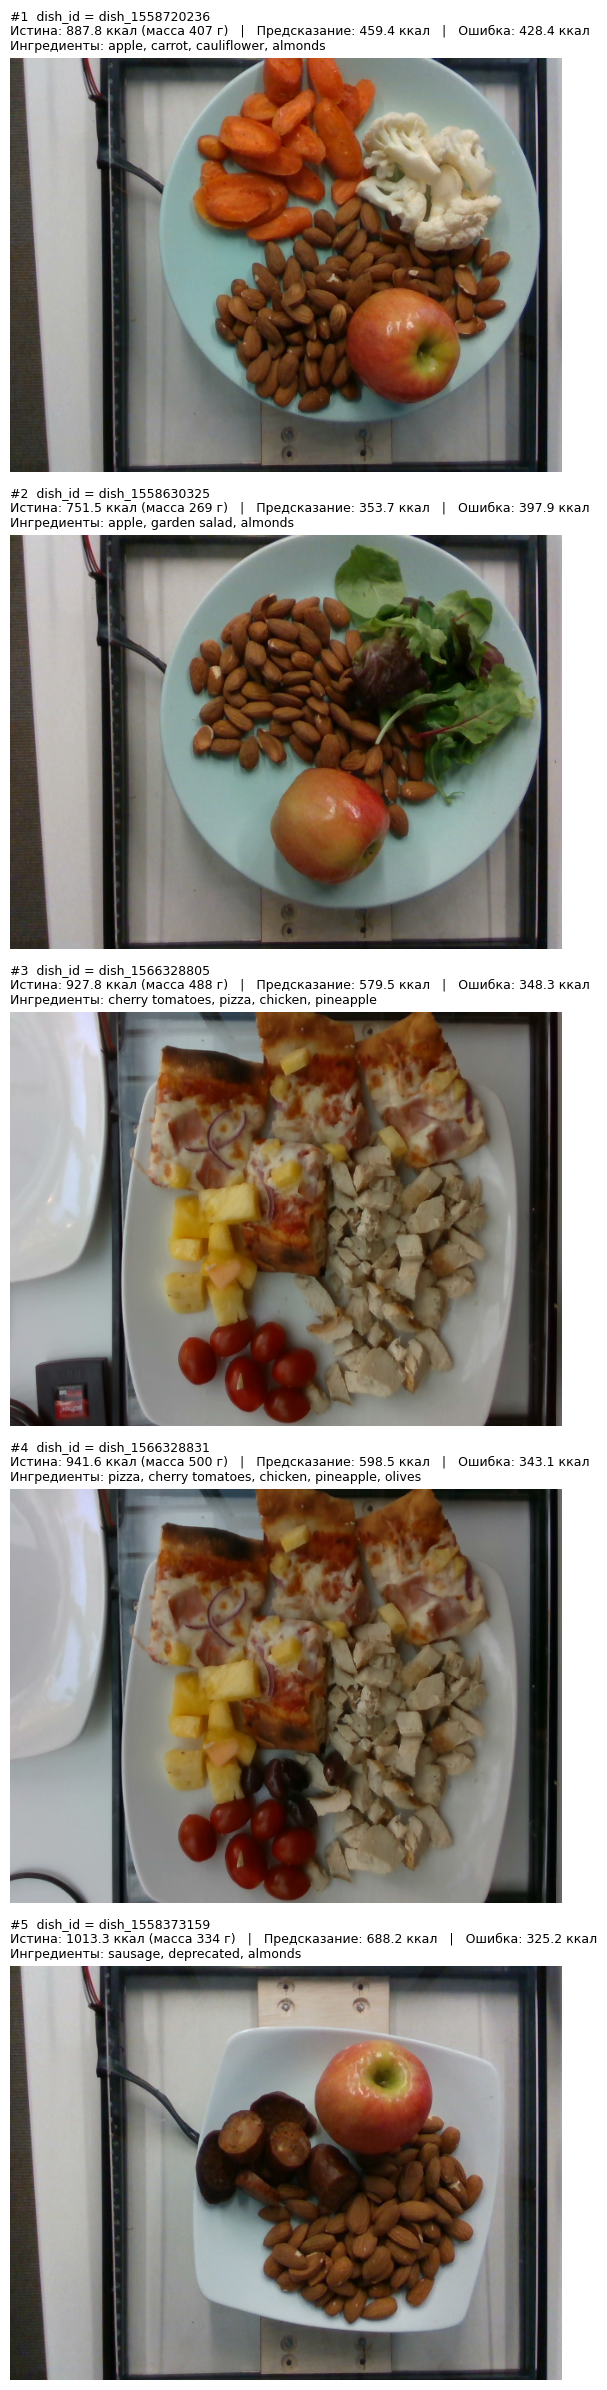

In [9]:
import matplotlib.pyplot as plt
from PIL import Image
import os

# Подтягиваем ингредиенты и массу из исходного df
ingr_lookup = dish.set_index("dish_id")[["ingredients_clean", "total_mass", "total_calories"]]

top5 = df_test.nlargest(5, "error").reset_index(drop=True)

fig, axes = plt.subplots(5, 1, figsize=(14, 24))
for i, row in top5.iterrows():
    ax = axes[i]
    dish_id = row["dish_id"]

    img_path = f"data/images/{dish_id}/rgb.png"
    try:
        img = Image.open(img_path).convert("RGB")
        ax.imshow(img)
    except FileNotFoundError:
        ax.text(0.5, 0.5, f"Нет изображения\n{img_path}",
                ha="center", va="center", fontsize=10)
        ax.set_facecolor("#eeeeee")

    ingr_text = ingr_lookup.loc[dish_id, "ingredients_clean"]
    if isinstance(ingr_text, str) and len(ingr_text) > 240:
        ingr_text = ingr_text[:240] + "..."

    title = (
        f"#{i+1}  dish_id = {dish_id}\n"
        f"Истина: {row['true_calories']:.1f} ккал (масса {row['true_mass']:.0f} г)   |   "
        f"Предсказание: {row['pred_calories']:.1f} ккал   |   Ошибка: {row['error']:.1f} ккал\n"
        f"Ингредиенты: {ingr_text}"
    )
    ax.set_title(title, fontsize=9, loc="left")
    ax.axis("off")

plt.tight_layout()
plt.show()

## 4.2. Анализ топ-5 ошибок

Визуальный разбор 5 худших предсказаний (все — недооценка калорийности):

| dish_id | Реально (ккал) | Предсказано | Ошибка | Масса | Ингредиенты (ключевые) |
|---|---|---|---|---|---|
| dish_1558720236 | 887.8 | 459.4 | **428.4** | 407 г | apple, carrot, cauliflower, **almonds** |
| dish_1558630325 | 751.5 | 353.7 | **397.9** | 269 г | apple, garden salad, **almonds** |
| dish_1566328805 | 927.8 | 579.5 | **348.3** | 488 г | pizza, chicken, **pineapple** |
| dish_1566328831 | 941.6 | 598.5 | **343.1** | 500 г | pizza, chicken, pineapple, **olives** |
| dish_1558373159 | 1013.3 | 688.2 | **325.2** | 334 г | sausage, **deprecated**, **almonds** |

### Выявленные причины ошибок

**1. Высокоплотные ингредиенты (almonds, olives).**
Миндаль = **580 ккал/100г**, оливки ≈ **115 ккал/100г**. Средняя плотность в train = 128 ккал/100г. Миндаль в **4.5× плотнее** среднего блюда. В train таких «калорийных бомб» мало → модель систематически недооценивает. На фото №1 миндаль занимает ~60% тарелки (~200 г → 1160 ккал только от орехов), но модель ориентируется на «яблоко + морковь + капуста» и предсказывает 459 ккал.

**2. Текстовая компонента плохо «привязана» к калорийности.**
DistilBERT обучен на общих текстах. Для него `almonds` и `apple` — равнозначные токены. Проекционный слой учится на частотности ингредиентов, а `almonds` встречается в train редко → веса остаются слабыми.

**3. Фото не передаёт плотность.**
Модель видит «горку орехов» и «горку салата» одинаково. Нет информации о глубине блюда, размере порции, весе. EfficientNet-B0 не может оценить, что миндаль в 10 раз плотнее салата визуально.

**4. Мусорные токены в тексте (`deprecated`).**
В примере №5 в списке есть `deprecated` — технический артефакт маппинга, а не ингредиент. Модель «сбивается», потому что такого слова нет в её смысловой картине.

### Общий вывод

Модель **отлично работает на «средних» блюдах** (медиана ошибки < 10 ккал, MAE 32.34 < 50), но **недооценивает экстремально калорийные** — с орехами, оливками, маслами, большими порциями. Это фундаментальное ограничение:
- в train мало примеров высокой плотности,
- фото не даёт информации о весе,
- текст используется, но не «знает» про калорийность слов.

### Гипотезы для улучшения (идеи на будущее)

- **Добавить в датасет признак `density_prior`** — если в ингредиентах есть «высокоплотные» слова (almonds, olive oil, butter, cheese) → повысить предсказание.
- **Учесть массу сильнее**: сейчас модель использует массу, но если домножить предсказанную плотность на массу с клиппингом (а не линейно) — это поможет большим порциям.
- **Убрать `deprecated` и подобные токены** на этапе препроцессинга.
- **Targeted loss**: увеличить вес ошибок на «калорийных» примерах (weighted MAE).
- **Больше эпох** — на 20-й эпохе `val_MAE` ещё снижалась (23.90), можно попробовать 30–40.

In [10]:
from google.colab import files
files.download("/content/calorie-project/best_calorie_model.pth")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>